> **Portfolio presentation copy of a collaborative course project.** Original MATH 189 team: Amber Tang, Emily Holguin, Hikari Gregersen, and Yingchen Lin. The Python analysis code comes from the team notebook; explanatory text in the interaction-result and conclusion sections has been corrected for statistical interpretation. The original team repository is `HGregersen/MATH189Project` (private).

# MATH 189 - Final Project - Social Media Mental Health Analysis

# Names

- Amber Tang
- Emily Holguin
- Hikari Gregersen
- Yingchen Lin

# Research Question

Do the effects of social media addiction differ by age, such that younger students experience greater mental health impacts while older students experience increased relationship conflict?

# Background

This problem is important because social media use is nearly universal among students aged 16-25, yet its psychological and social effects may not be the same across different stages of development. Adolescence and early adulthood are distance developmental periods characterized by different emotional, cognitive, and relational challenges. If the impact of social media addiction varies by age, then treating all students as a single group could mask meaningful differences in vulnerability and outcomes. 

Younger students, particularly high schoolers, are in critical stages of identity formation and are often more sensitive to peer comparison and social validation. If social media addiction disproportionately affects their mental health, it could contribute to long term emotional difficulties during a formative developmental window, making early intervention especially important. In contrast, older students like undergraduates or graduate students often navigate more complex, romantic, social, and professional relationships. If social media addiction is more strongly linked to relationship conflict in this age group, it may interfere with relationship stability, academic success, and overall life satisfaction. 

More broadly, this research helps identify for whom and in what ways social media addition is most harmful. Recognizing age as a moderating factor can guide more targeted prevention effects and support programs for students. 

## Prior Work

There were already several exploratory and basic analytical steps performed in relation to the Kaggle in the [Code](https://www.kaggle.com/datasets/adilshamim8/social-media-addiction-vs-relationships/code) section. Most of the notebooks began by loading and reviewing the data to confirm that there weren't any missing values and to check the dataset structure. They then conduct EDA using descriptive statistics and visualizations with histograms, bar charts, etc. to examine patterns in variables such as `Avg_Daily_Usage_Hours`, `Addicted_Score`, `Relationship_Status`, `Sleep_Hours_Per_Night`, and `Mental_Health_Score`. Some also explored relationships between variables, like by comparing average daily usage hours or relationship conflicts with addiction scores. These analyses primarily focused on how social media usage could affect those surveyed, but didn't directly analyze whether `Age` would influence these impacts, which is our focus.

# Hypothesis

We expect to find that the effects of social media addiction differ by age group. Specifically, we predict that the high schoolers will show stronger associations between social media addiction and negative mental health scores. We believe this could be related to being more susceptible to peer pressure and identity development. On the other hand, we expect older students to show stronger associations between social media addiction and the number of relationship conflicts. This could result from the increased responsibilities of adulthood, more complex romantic relationships, and greater expectations for emotional maturity. Overall, we anticipate that age will moderate the relationship between social media addiction and its consequences, such that mental health outcomes will be more strongly impacted among younger students and relational impacts will be more impacted with older students.


# Data

## Data Overview

We plan on using the data from [this](https://www.kaggle.com/datasets/adilshamim8/social-media-addiction-vs-relationships) dataset on Kaggle. This data comes from an anonymized survey which recorded students’ demographics, various measurements of their social media addiction levels and metrics of several quality of life indicators. Participants were recruited to this study through university mailing lists and social media platforms across multiple different countries in 2025. Participants included students aged 16-25 enrolled in high school, undergraduate and graduate programs. One source of potential bias comes from the participants being volunteers. It is possible that students who were more addicted to social media, or who experienced more severe mental health impacts were less likely to fill out the survey.
This dataset has many useful variables for our analysis. We will use the `Age` variable to categorize participants for further analysis. Additionally, the dataset provides variables describing participants’ addiction level to social media. It includes participants’ average daily usage hours, as well as their Bergen Social Media addiction score. Finally, it includes various measures of quality of life including participants’ self-rated mental health score, number of relationship conflicts caused by social media, impact of social media on academics and average hours of sleep per night.

## Dataset

In [8]:
# import data sets and any libraries needed
import numpy as np
import pandas as pd
import seaborn as sns

import matplotlib.pyplot as plt

import statsmodels.api as sm
import statsmodels.formula.api as smf
import scipy.stats as stats

In [9]:
data = pd.read_csv("Students Social Media Addiction.csv")
print("Shape of data:", data.shape)
data.head()

Shape of data: (705, 13)


,Student_ID,Age,Gender,Academic_Level,Country,Avg_Daily_Usage_Hours,Most_Used_Platform,Affects_Academic_Performance,Sleep_Hours_Per_Night,Mental_Health_Score,Relationship_Status,Conflicts_Over_Social_Media,Addicted_Score
0,1,19,Female,Undergraduate,Bangladesh,5.2,Instagram,Yes,6.5,6,In Relationship,3,8
1,2,22,Male,Graduate,India,2.1,Twitter,No,7.5,8,Single,0,3
2,3,20,Female,Undergraduate,USA,6.0,TikTok,Yes,5.0,5,Complicated,4,9
3,4,18,Male,High School,UK,3.0,YouTube,No,7.0,7,Single,1,4
4,5,21,Male,Graduate,Canada,4.5,Facebook,Yes,6.0,6,In Relationship,2,7


In [10]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 705 entries, 0 to 704
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Student_ID                    705 non-null    int64  
 1   Age                           705 non-null    int64  
 2   Gender                        705 non-null    object 
 3   Academic_Level                705 non-null    object 
 4   Country                       705 non-null    object 
 5   Avg_Daily_Usage_Hours         705 non-null    float64
 6   Most_Used_Platform            705 non-null    object 
 7   Affects_Academic_Performance  705 non-null    object 
 8   Sleep_Hours_Per_Night         705 non-null    float64
 9   Mental_Health_Score           705 non-null    int64  
 10  Relationship_Status           705 non-null    object 
 11  Conflicts_Over_Social_Media   705 non-null    int64  
 12  Addicted_Score                705 non-null    int64  
dtypes: fl

We can see that there are no null points in our data.\
\
Data types of each variable of the dataset:
> `Student_ID` -> continuous quantitative integers [can be removed since they are unique identifiers for the respondents] \
> `Age` -> continuous quantitative integers [comes from range of 18 to 24] \
> `Gender` -> nominal categorical variables [Male, Female] \
> `Academic_Level` -> ordinal categorical variables [High School, Undergraduate, Graduate] \
> `Country` -> nominal categorical variables [110 different countries listed] \
> `Avg_Daily_Usage_Hours` -> continous quantiative variables [comes from range of 2 to 9] \
> `Most_Used_Platform` -> nominal categorical variables [12 different platforms listed] \
> `Affects_Academic_Performance` -> nominal categorical variables [Yes, No] \
> `Sleep_Hours_Per_Night` -> continous quantiative variables [comes from range of 3 to 10] \
> `Mental_Health_Score` -> continuous quantitative integers [comes from range of 4 to 9] \
> `Relationship_Status` -> nominal categorical variables [In Relationship, Single, Complicated] \
> `Conflicts_Over_Social_Media` -> continuous quantitative integers [comes from range of 0 to 5] \
> `Addicted_Score` -> continuous quantitative integers [comes from range of 2 to 9]

Converting to categorical variables in dataframe:

In [11]:
data.drop(columns="Student_ID", inplace=True)
data["Gender"] = pd.Categorical(data["Gender"])
data["Academic_Level"] = pd.Categorical(data["Academic_Level"])
data["Affects_Academic_Performance"] = pd.Categorical(data["Affects_Academic_Performance"])
data["Relationship_Status"] = pd.Categorical(data["Relationship_Status"])

In [12]:
print('New data types:')
print(data.info(), '\n\nNew shape:', data.shape)

New data types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 705 entries, 0 to 704
Data columns (total 12 columns):
 #   Column                        Non-Null Count  Dtype   
---  ------                        --------------  -----   
 0   Age                           705 non-null    int64   
 1   Gender                        705 non-null    category
 2   Academic_Level                705 non-null    category
 3   Country                       705 non-null    object  
 4   Avg_Daily_Usage_Hours         705 non-null    float64 
 5   Most_Used_Platform            705 non-null    object  
 6   Affects_Academic_Performance  705 non-null    category
 7   Sleep_Hours_Per_Night         705 non-null    float64 
 8   Mental_Health_Score           705 non-null    int64   
 9   Relationship_Status           705 non-null    category
 10  Conflicts_Over_Social_Media   705 non-null    int64   
 11  Addicted_Score                705 non-null    int64   
dtypes: category(4), float64(2), int64(

## Exploratory Data Analysis
To start, we performed exploratory data analysis to visualize the distribution of data across different variables. Since our hypothesis is that the effects of social media addiction differ by age group, we begin by looking at the distribution of age in our dataset.

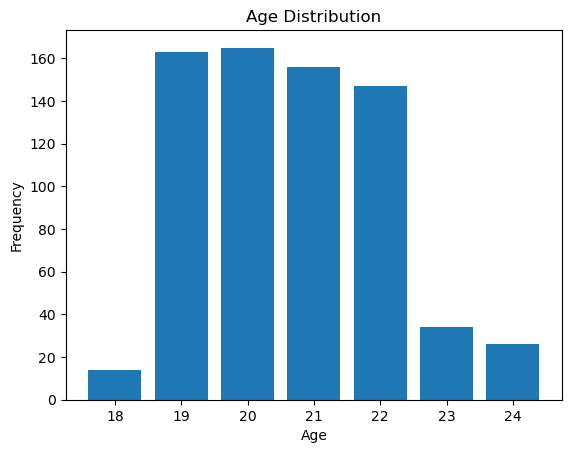

In [13]:
# Create bar graph of age
age_counts = data['Age'].value_counts().sort_index()

plt.figure()
plt.bar(age_counts.index, age_counts.values)
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.title('Age Distribution')
plt.show()

Next we do the same to visualize academic level:


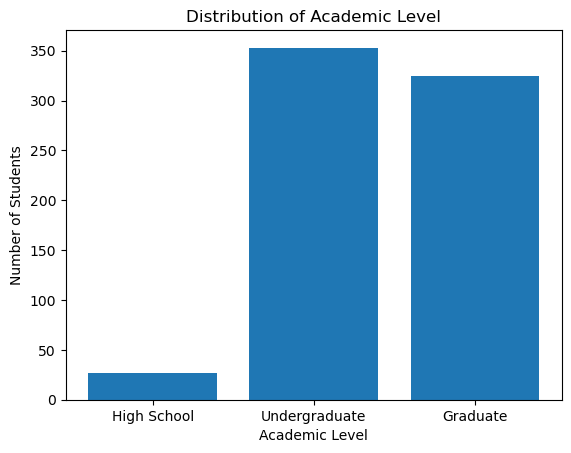

In [14]:
# Create bar graph of academic level 
academic_counts = data['Academic_Level'].value_counts()

order = ['High School', 'Undergraduate', 'Graduate']
academic_counts = academic_counts.reindex(order)

plt.figure()
plt.bar(academic_counts.index, academic_counts.values)
plt.xlabel('Academic Level')
plt.ylabel('Number of Students')
plt.title('Distribution of Academic Level')
plt.show()

The graphs show that the dataset is heavily concentrated among students aged 19–22, indicating it primarily represents typical college-age individuals. The academic level distribution further confirms this, with most participants being undergraduates and graduates, while high school students make up a very small portion of the sample. Because of this imbalance, any conclusions drawn about “students” may mainly reflect college students rather than younger high school students, introducing potential bias and limiting how broadly the results can be generalized.

To explore whether social media addiction differs by age group, we first examined how `Addicted_Score` varies across academic levels. Comparing addiction levels among high school, undergraduate, and graduate students allows us to assess whether certain age groups exhibit higher overall tendencies toward social media addiction before analyzing its specific impacts on mental health and relationship conflict.

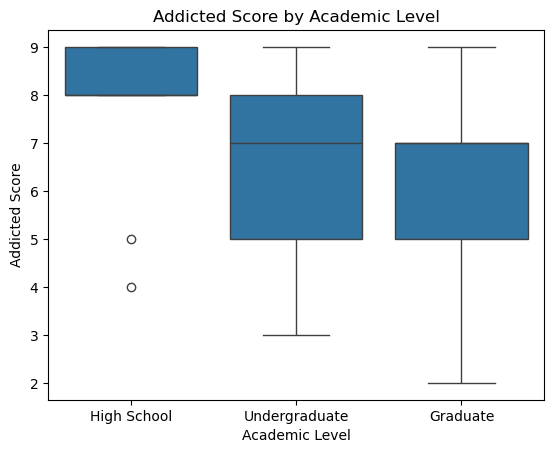

In [15]:
order = ['High School', 'Undergraduate', 'Graduate']

plt.figure()
sns.boxplot(x='Academic_Level',
            y='Addicted_Score',
            data=data,
            order=order)

plt.xlabel('Academic Level')
plt.ylabel('Addicted Score')
plt.title('Addicted Score by Academic Level')
plt.show()

The boxplot shows that high school students appear to have the highest median addicted scores, with most values clustered toward the upper end of the scale, although there are a few lower outliers. Undergraduate students have a slightly lower median and a wider spread, indicating more variability in addiction levels. Graduate students show a similar or slightly lower median compared to undergraduates, with a broad distribution as well. Overall, addiction levels appear relatively high across all academic levels, but high school students may exhibit slightly stronger addiction tendencies, though the small sample size for this group should be considered when interpreting these differences.

## Data Visualization

In this section, we extend our exploratory analysis by creating visualizations that examine the relationships between key variables in our dataset. In particular, we focus on how social media addiction scores relate to mental health outcomes and relationship conflicts. These visualizations help us better understand patterns in the data and provide preliminary insights before conducting formal statistical modeling.

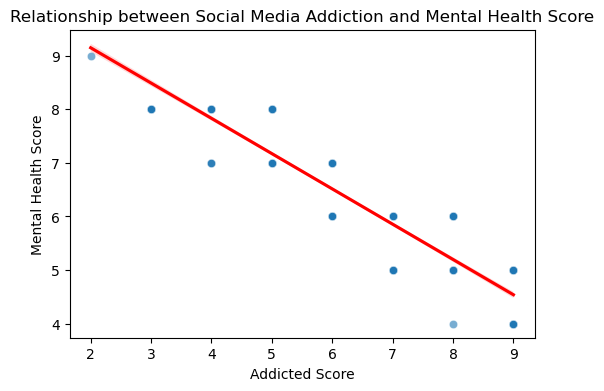

In [16]:
plt.figure(figsize=(6,4))
sns.scatterplot(data=data, x="Addicted_Score", y="Mental_Health_Score", alpha=0.6)
sns.regplot(data=data, x="Addicted_Score", y="Mental_Health_Score", scatter=False, color="red")

plt.title("Relationship between Social Media Addiction and Mental Health Score")
plt.xlabel("Addicted Score")
plt.ylabel("Mental Health Score")
plt.show()

The first visualization explores the relationship between social media addiction scores and mental health scores. The scatter plot suggests that students with higher addiction scores tend to report poorer mental health outcomes. Although the relationship shows noticeable variability across individuals, the fitted regression line indicates a general trend in which increased addiction levels are associated with lower mental health scores. 

This pattern is consistent with our research question, which examines whether higher levels of social media addiction are linked to negative psychological outcomes among students.

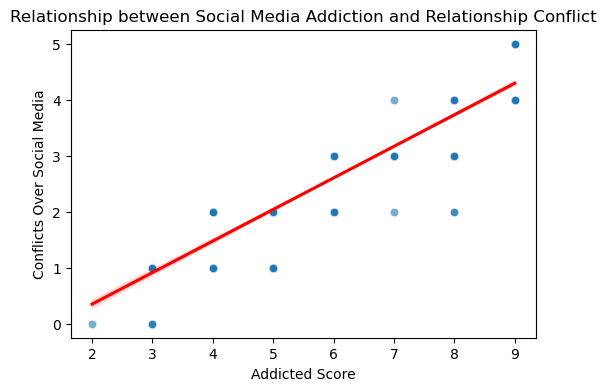

In [17]:
plt.figure(figsize=(6,4))

sns.scatterplot(data=data, x="Addicted_Score", y="Conflicts_Over_Social_Media", alpha=0.6)
sns.regplot(data=data, x="Addicted_Score", y="Conflicts_Over_Social_Media", scatter=False, color="red")

plt.title("Relationship between Social Media Addiction and Relationship Conflict")
plt.xlabel("Addicted Score")
plt.ylabel("Conflicts Over Social Media")

plt.show()

The second visualization examines the relationship between social media addiction and conflicts related to social media use. The scatter plot suggests that students with higher addiction scores tend to report more conflicts related to social media. The fitted regression line indicates a positive relationship between these variables.

This result supports the idea that excessive social media use may contribute to interpersonal tensions or disagreements, potentially affecting students’ relationships with others.

# Methodology

To examine the relationship between social media addiction and student outcomes, we estimate a series of linear regression models. Linear regression is appropriate because both outcome variables — mental health score and number of social-media-related relationship conflicts — are continuous measures.

We first estimate baseline models examining the association between addiction scores and each outcome variable. We then extend these models by including age and academic level as control variables to account for demographic differences among students. Finally, we test our main hypothesis by including an interaction term between addiction score and age to evaluate whether the effects of social media addiction differ across age groups.

# Modeling

In this section, we use regression models to formally examine the relationships suggested by our visualizations. Our primary goal is to evaluate whether social media addiction (measured by `Addicted_Score`) is associated with (1) mental health outcomes (`Mental_Health_Score`) and (2) relationship conflict related to social media (`Conflicts_Over_Social_Media`). 

We begin with simple baseline linear regression models and then extend them by including additional predictors. Finally, we test our main hypothesis that the effects of social media addiction may differ by age group by including an interaction between addiction score and age.

## Model 1
### Model 1A: Mental Health ~ Addiction

In [18]:
m1_mental = smf.ols("Mental_Health_Score ~ Addicted_Score", data=data).fit()
print(m1_mental.summary())

                             OLS Regression Results                            
Dep. Variable:     Mental_Health_Score   R-squared:                       0.893
Model:                             OLS   Adj. R-squared:                  0.893
Method:                  Least Squares   F-statistic:                     5875.
Date:                 Mon, 23 Nov 2026   Prob (F-statistic):               0.00
Time:                         20:17:40   Log-Likelihood:                -282.07
No. Observations:                  705   AIC:                             568.1
Df Residuals:                      703   BIC:                             577.3
Df Model:                            1                                         
Covariance Type:             nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept         10.4623      0.0

**Model 1a (Baseline):** We first fit a simple linear regression with mental health score as the response variable and addiction score as the predictor. This model provides a baseline estimate of the association between social media addiction and mental health outcomes. A negative coefficient for `Addicted_Score` would indicate that higher addiction scores are associated with lower mental health scores, consistent with the trend seen in our visualization. The p-value of ~0 shows that `Addicted_Score` is statistically significant when predicting `Mental_Health_Score`.

### Model 1B: Conflicts ~ Addiction

In [19]:
m1_conflict = smf.ols("Conflicts_Over_Social_Media ~ Addicted_Score", data=data).fit()
print(m1_conflict.summary())

                                 OLS Regression Results                                
Dep. Variable:     Conflicts_Over_Social_Media   R-squared:                       0.872
Model:                                     OLS   Adj. R-squared:                  0.871
Method:                          Least Squares   F-statistic:                     4771.
Date:                         Mon, 23 Nov 2026   Prob (F-statistic):          1.55e-315
Time:                                 20:17:42   Log-Likelihood:                -246.08
No. Observations:                          705   AIC:                             496.2
Df Residuals:                              703   BIC:                             505.3
Df Model:                                    1                                         
Covariance Type:                     nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------

**Model 1b (Baseline):** Next, we fit a simple linear regression with relationship conflict as the response variable and addiction score as the predictor. A positive coefficient for `Addicted_Score` would suggest that students with higher addiction scores tend to report more conflicts related to social media, aligning with the positive trend observed in our visualization. The p-value of ~0 shows that `Addicted_Score` is a statistically significant factor to predict `Conflicts_Over_Social_Media`.

## Model 2
### Model 2A: Mental Health ~ Addiction + Age + Academic Level

In [20]:
m2_mental = smf.ols("Mental_Health_Score ~ Addicted_Score + Age + C(Academic_Level)", data=data).fit()
print(m2_mental.summary())

                             OLS Regression Results                            
Dep. Variable:     Mental_Health_Score   R-squared:                       0.894
Model:                             OLS   Adj. R-squared:                  0.893
Method:                  Least Squares   F-statistic:                     1473.
Date:                 Mon, 23 Nov 2026   Prob (F-statistic):               0.00
Time:                         20:17:44   Log-Likelihood:                -279.84
No. Observations:                  705   AIC:                             569.7
Df Residuals:                      700   BIC:                             592.5
Df Model:                            4                                         
Covariance Type:             nonrobust                                         
                                         coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------

**Model 2a (Controls):** We extend the baseline model by adding `Age` and `Academic_Level` as additional predictors. Including these variables helps us evaluate whether the association between addiction score and mental health remains after accounting for basic demographic/education differences in the sample. We can see that the `Addicted_Score` is a strong and statistically significant predictor with a coefficient of -0.657 and p-value 0.001. The negative coefficient indicates that higher addiction scores are associated with lower mental health scores, suggesting poorer mental health outcomes among more addicted students.

`Age` is seemingly not statistically significant as it's p-value is 0.123, indicating that age alone does not strongly predict mental health in this model. `Academic_Level` also does not show significant differences at the 0.05 level, with both p-values being around .06.

The model explains a large proportion of the variance in mental health scores as $R^2 = 0.894$, suggesting a very strong overall fit.

### Model 2B: Conflicts ~ Addiction + Age + Academic Level

In [21]:
m2_conflict = smf.ols("Conflicts_Over_Social_Media ~ Addicted_Score + Age + C(Academic_Level)", data=data).fit()
print(m2_conflict.summary())

                                 OLS Regression Results                                
Dep. Variable:     Conflicts_Over_Social_Media   R-squared:                       0.873
Model:                                     OLS   Adj. R-squared:                  0.872
Method:                          Least Squares   F-statistic:                     1204.
Date:                         Mon, 23 Nov 2026   Prob (F-statistic):          5.15e-312
Time:                                 20:17:45   Log-Likelihood:                -241.92
No. Observations:                          705   AIC:                             493.8
Df Residuals:                              700   BIC:                             516.6
Df Model:                                    4                                         
Covariance Type:                     nonrobust                                         
                                         coef    std err          t      P>|t|      [0.025      0.975]
-----------------

**Model 2b (Controls):** We fit an analogous model for relationship conflict, adding `Age` and `Academic_Level` as controls. This allows us to check whether addiction score is still associated with conflict outcomes when adjusting for these factors.

We can see that the `Addicted_Score` is again a strong and statistically significant predictor with a coefficient of 0.562 and p-value ~0. The positive coefficient indicates that higher addiction scores are associated with greater levels of relationship conflict related to social media.

`Age` and `Academic_Level` are also not statistically significant predictors in this model, suggesting that these factors alone do not strongly influence conflict levels when the `Addicted_Score` is included.

The model explains a large portion of the variance in conflict scores with $R^2 = 0.873$.

**Model 2a/b Analysis:** From these models, we have found that the `Addicted_Score` strongly predicts both poorer mental health and increased relationship conflict and that `Age` alone can not explain these differences. This leads us to test the interaction effects between addiction and age to determine whether the impact of addiction differs across age groups.

## Model 3
### Model 3A: Interaction Test for Addiction & Age for Mental Health

In [22]:
m3_mental = smf.ols("Mental_Health_Score ~ Addicted_Score * Age + C(Academic_Level)", data=data).fit()
print(m3_mental.summary())

                             OLS Regression Results                            
Dep. Variable:     Mental_Health_Score   R-squared:                       0.895
Model:                             OLS   Adj. R-squared:                  0.894
Method:                  Least Squares   F-statistic:                     1186.
Date:                 Mon, 23 Nov 2026   Prob (F-statistic):               0.00
Time:                         20:17:47   Log-Likelihood:                -277.30
No. Observations:                  705   AIC:                             566.6
Df Residuals:                      699   BIC:                             594.0
Df Model:                            5                                         
Covariance Type:             nonrobust                                         
                                         coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------

**Model 3A (Interaction — corrected interpretation for portfolio copy):** The fitted interaction coefficient `Addicted_Score:Age` is -0.0127 (p = 0.025). In this model, the conditional association between addiction score and mental-health score becomes **more negative as age increases**, not less negative. For example, the modeled slope for a one-point increase in addiction score is approximately -0.624 at age 18 and -0.700 at age 24. This contradicts our original directional hypothesis for the mental-health outcome. The model has $R^2 = 0.895$. This is an association, not evidence of causation.


### Model 3B: Interaction Test for Addiction & Age for Conflicts

In [23]:
m3_conflict = smf.ols("Conflicts_Over_Social_Media ~ Addicted_Score * Age + C(Academic_Level)", data=data).fit()
print(m3_conflict.summary())

                                 OLS Regression Results                                
Dep. Variable:     Conflicts_Over_Social_Media   R-squared:                       0.881
Model:                                     OLS   Adj. R-squared:                  0.880
Method:                          Least Squares   F-statistic:                     1038.
Date:                         Mon, 23 Nov 2026   Prob (F-statistic):          1.53e-320
Time:                                 20:17:49   Log-Likelihood:                -218.47
No. Observations:                          705   AIC:                             448.9
Df Residuals:                              699   BIC:                             476.3
Df Model:                                    5                                         
Covariance Type:                     nonrobust                                         
                                         coef    std err          t      P>|t|      [0.025      0.975]
-----------------

**Model 3B (Interaction):** The fitted interaction coefficient `Addicted_Score:Age` for the relationship-conflict outcome is +0.0360 (p < 0.001). In this model, the association between addiction score and relationship-conflict score becomes more positive as age increases. The model has $R^2 = 0.881$.

**Interpretation of the two interaction results (portfolio clarification):** Both models show evidence of age-varying associations, but the mental-health interaction is in the **opposite direction** from our original prediction: the negative addiction–mental-health association is stronger at older ages. The relationship-conflict interaction aligns with the predicted stronger positive association at older ages. Neither regression establishes causality.


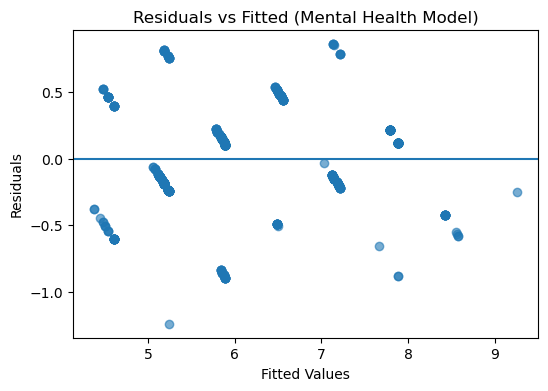

In [24]:
fitted = m3_mental.fittedvalues
resid = m3_mental.resid

plt.figure(figsize=(6,4))
plt.scatter(fitted, resid, alpha=0.6)
plt.axhline(0)
plt.title("Residuals vs Fitted (Mental Health Model)")
plt.xlabel("Fitted Values")
plt.ylabel("Residuals")
plt.show()

We also examine a residuals-versus-fitted plot and it seems as though there is no strong systematic curve or funnel shape, leading us to believe that the linearity and constant variance assumptions of the linear model are reasonable.

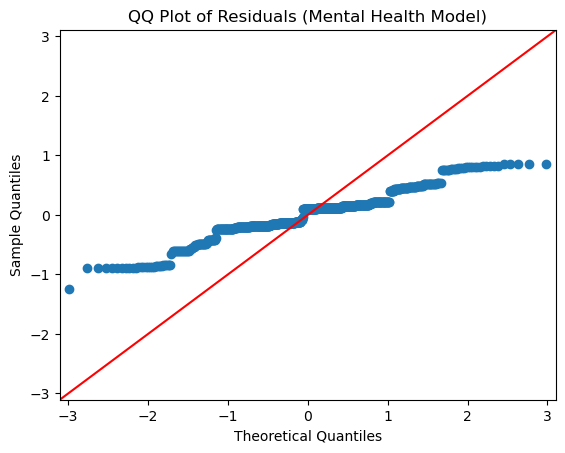

In [25]:
# checking if the residuals are normally distributed
sm.qqplot(m3_mental.resid, line='45')
plt.title("QQ Plot of Residuals (Mental Health Model)")
plt.show()

The QQ plot suggests that the residuals are not perfectly normally distributed, as many of the points deviate from the 45-degree reference line, with the points appearing somewhat flatter than the line.

# Type of Analyses 

In this project, we performed several statistical analyses to study the relationship between social media addiction and student outcomes. We first conducted exploratory data analysis to understand the distribution of the variables and visualize key relationships. We then fitted several linear regression models, including baseline models, models with control variables, and interaction models to test whether age moderates the effects of social media addiction. We also examined diagnostic plots to evaluate the assumptions of the regression models.

# Interpretation of Results (portfolio clarification)
Higher addiction scores are associated with lower mental-health scores and higher social-media-related relationship-conflict scores in this dataset. Both associations persist in models controlling for age and academic level.

Age interacts with addiction score in both fitted models. The negative interaction in the mental-health model indicates a **stronger negative** association at older ages, while the positive interaction in the conflict model indicates a **stronger positive** association at older ages. Thus, only the conflict result follows the original directional hypothesis. All results are associational, conditional on the model and dataset assumptions.


# Relation to Project Proposal

The final analysis largely follows the plan outlined in the original project proposal. In the proposal, we aimed to examine how social media addiction relates to mental health and relationship conflict among students and whether these relationships differ by age. The final report addresses these questions by using exploratory data analysis and regression models, including interaction terms to test the role of age. Overall, the results provide empirical evidence that aligns with the original research goals.

# Limitations

Several limitations should be kept in mind when interpreting these findings.

First, the data rely on self-reports from students about their social media use, mental health, and relationship conflicts. While surveys are commonly used in this type of research, self-reported data still carry the risk of bias. Participants may underreport or overreport their behaviors, meaning the values may not perfectly reflect their actual experiences.

Second, because the data are cross-sectional, they only capture a snapshot in time. This means the regression results reflect associations rather than cause-and-effect relationships. For example, although higher social media addiction scores are associated with poorer mental health, it is unclear whether excessive social media use leads to psychological distress or whether students experiencing mental health difficulties are more likely to use social media excessively.

The sample also presents some limitations. Undergraduate and graduate students make up a much larger share of the dataset than high school students. This imbalance makes it more difficult to draw reliable comparisons across age groups and may affect the interaction analyses involving age.

Finally, some relevant variables are not included in the dataset. Factors such as personality traits, family background, academic stress, or pre-existing mental health conditions could influence both social media addiction and well-being. Because these variables are not observed, the regression models may not fully capture all relevant influences.

Given these limitations, the findings should be interpreted as associations rather than causal conclusions. Future research using longitudinal data or more balanced samples could help clarify the direction and nature of these relationships.

# Conclusion (portfolio clarification)
We analyzed how social-media addiction scores relate to mental-health and relationship-conflict scores in a 705-row publicly available dataset. Higher addiction scores were associated with lower mental-health scores and more relationship conflict. The interaction models suggested that these associations vary with age.

Contrary to the original directional hypothesis, the negative mental-health association was **stronger at older ages** in the fitted interaction model. The positive relationship-conflict association also became stronger with age. Because the study relies on cross-sectional, self-reported data and has an imbalanced age/academic-level distribution, these findings do not establish causality or generalize automatically to broader student populations. The dataset's underlying survey provenance has not been independently verified as part of this project.
